
# Inteligencia Artificial — Tarea 2

## Punto 1. Regresión lineal y sobreajuste

En este trabajo se utiliza el conjunto de datos Concrete Compressive Strength para predecir la resistencia a la compresión del concreto a partir de ocho variables cuantitativas.

Se realiza un análisis exploratorio, se limpian los datos y se comparan los resultados de una regresión lineal normal con un modelo de regresión polinómica para estudiar el sobreajuste.

## Punto 2. Implementación de Ridge

Se implementará una clase propia llamada `MyRidge`, utilizando NumPy y la solución cerrada de la regresión Ridge, sin utilizar Scikit-learn dentro de la clase.


In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Ruta del conjunto de datos limpio
ruta = Path("data/concrete_data_limpio.csv")

# Comprobar que el archivo existe
if not ruta.exists():
    raise FileNotFoundError(
        f"No se encontro el archivo: {ruta.resolve()}"
    )

# Cargar los datos
df = pd.read_csv(ruta)

print("DATOS CARGADOS CORRECTAMENTE")
print("Dimensiones:", df.shape)

# Mostrar las primeras cinco filas
display(df.head())


DATOS CARGADOS CORRECTAMENTE
Dimensiones: (1005, 9)


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [2]:

# 1. Revisar los nombres de las columnas
print("NOMBRES DE LAS COLUMNAS:")
print(df.columns.tolist())

# 2. Revisar los tipos de datos
print("\nTIPOS DE DATOS:")
print(df.dtypes)

# 3. Comprobar valores ausentes
print("\nVALORES AUSENTES POR COLUMNA:")
print(df.isnull().sum())
print("Total de valores ausentes:", df.isnull().sum().sum())

# 4. Comprobar duplicados
print("\nFILAS DUPLICADAS:")
print(df.duplicated().sum())

# 5. Obtener estadísticas descriptivas
print("\nESTADISTICAS DESCRIPTIVAS:")
display(df.describe().round(2))

# 6. Separar las variables predictoras del objetivo
objetivo = "concrete_compressive_strength"

X = df.drop(columns=[objetivo])
y = df[objetivo]

print("\nRESUMEN DE LAS VARIABLES")
print("Numero de filas:", df.shape[0])
print("Numero de columnas:", df.shape[1])
print("Variables predictoras:", X.shape[1])
print("Variable objetivo:", objetivo)


NOMBRES DE LAS COLUMNAS:
['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age', 'concrete_compressive_strength']

TIPOS DE DATOS:
cement                           float64
blast_furnace_slag               float64
fly_ash                          float64
water                            float64
superplasticizer                 float64
coarse_aggregate                 float64
fine_aggregate                   float64
age                                int64
concrete_compressive_strength    float64
dtype: object

VALORES AUSENTES POR COLUMNA:
cement                           0
blast_furnace_slag               0
fly_ash                          0
water                            0
superplasticizer                 0
coarse_aggregate                 0
fine_aggregate                   0
age                              0
concrete_compressive_strength    0
dtype: int64
Total de valores ausentes: 0

FILAS DUPLICADAS:
0

ESTADISTICAS D

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
count,1005.00,1005.00,1005.00,1005.00,1005.00,1005.00,1005.00,1005.00,1005.00
mean,278.63,72.04,55.54,182.08,6.03,974.38,772.69,45.86,35.25
std,104.34,86.17,64.21,21.34,5.92,77.58,80.34,63.73,16.28
min,102.00,0.00,0.00,121.80,0.00,801.00,594.00,1.00,2.33
25%,190.70,0.00,0.00,166.60,0.00,932.00,724.30,7.00,23.52
50%,265.00,20.00,0.00,185.70,6.10,968.00,780.00,28.00,33.80
75%,349.00,142.50,118.30,192.90,10.00,1031.00,822.20,56.00,44.87
max,540.00,359.40,200.10,247.00,32.20,1145.00,992.60,365.00,82.60



RESUMEN DE LAS VARIABLES
Numero de filas: 1005
Numero de columnas: 9
Variables predictoras: 8
Variable objetivo: concrete_compressive_strength


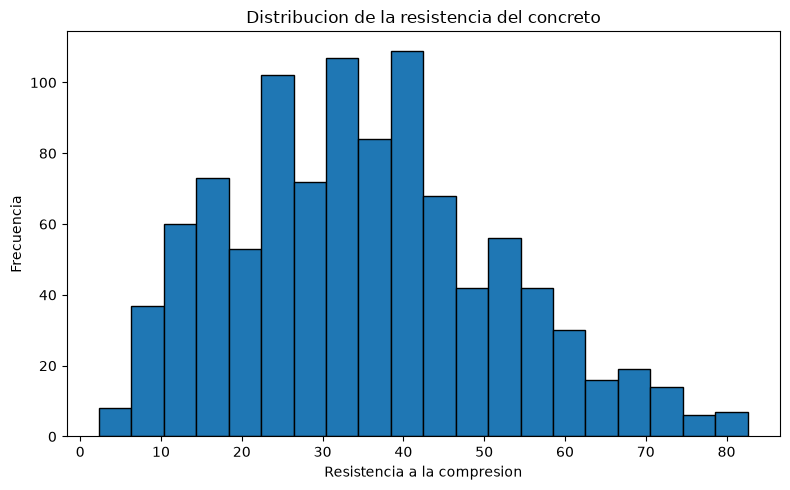

In [3]:

# Histograma de la resistencia a la compresion del concreto

plt.figure(figsize=(8, 5))

plt.hist(
    y,
    bins=20,
    edgecolor="black"
)

plt.title("Distribucion de la resistencia del concreto")
plt.xlabel("Resistencia a la compresion")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()


In [4]:

from sklearn.model_selection import train_test_split

# Dividir los datos: 80% para entrenar y 20% para probar
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("DIVISION DE LOS DATOS")
print("Ejemplos de entrenamiento:", X_train.shape[0])
print("Ejemplos de prueba:", X_test.shape[0])
print("Variables predictoras:", X_train.shape[1])


DIVISION DE LOS DATOS
Ejemplos de entrenamiento: 804
Ejemplos de prueba: 201
Variables predictoras: 8


In [5]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Crear el modelo
modelo_lineal = LinearRegression()

# 2. Entrenar el modelo con los datos de entrenamiento
modelo_lineal.fit(X_train, y_train)

# 3. Generar predicciones
pred_train_lineal = modelo_lineal.predict(X_train)
pred_test_lineal = modelo_lineal.predict(X_test)

# 4. Calcular el RMSE
rmse_train_lineal = mean_squared_error(
    y_train, pred_train_lineal
) ** 0.5

rmse_test_lineal = mean_squared_error(
    y_test, pred_test_lineal
) ** 0.5

# 5. Calcular R2
r2_train_lineal = r2_score(y_train, pred_train_lineal)
r2_test_lineal = r2_score(y_test, pred_test_lineal)

# 6. Mostrar los resultados
print("REGRESION LINEAL NORMAL")
print("------------------------------")
print(f"RMSE de entrenamiento: {rmse_train_lineal:.4f}")
print(f"RMSE de prueba:        {rmse_test_lineal:.4f}")
print(f"R2 de entrenamiento:   {r2_train_lineal:.4f}")
print(f"R2 de prueba:          {r2_test_lineal:.4f}")


REGRESION LINEAL NORMAL
------------------------------
RMSE de entrenamiento: 10.0018
RMSE de prueba:        11.1913
R2 de entrenamiento:   0.6099
R2 de prueba:          0.5802


In [6]:

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Crear un modelo polinomico de grado 4
modelo_polinomico = make_pipeline(
    PolynomialFeatures(degree=4, include_bias=False),
    LinearRegression()
)

# Entrenar el modelo
modelo_polinomico.fit(X_train, y_train)

# Realizar predicciones
pred_train_polinomico = modelo_polinomico.predict(X_train)
pred_test_polinomico = modelo_polinomico.predict(X_test)

# Calcular RMSE de entrenamiento y prueba
rmse_train_polinomico = mean_squared_error(
    y_train, pred_train_polinomico
) ** 0.5

rmse_test_polinomico = mean_squared_error(
    y_test, pred_test_polinomico
) ** 0.5

# Calcular R2 de entrenamiento y prueba
r2_train_polinomico = r2_score(
    y_train, pred_train_polinomico
)

r2_test_polinomico = r2_score(
    y_test, pred_test_polinomico
)

# Mostrar los resultados
print("REGRESION POLINOMICA DE GRADO 4")
print("--------------------------------")
print(f"RMSE de entrenamiento: {rmse_train_polinomico:.4f}")
print(f"RMSE de prueba:        {rmse_test_polinomico:.4f}")
print(f"R2 de entrenamiento:   {r2_train_polinomico:.4f}")
print(f"R2 de prueba:          {r2_test_polinomico:.4f}")


REGRESION POLINOMICA DE GRADO 4
--------------------------------
RMSE de entrenamiento: 3.4937
RMSE de prueba:        8.4865
R2 de entrenamiento:   0.9524
R2 de prueba:          0.7586


In [7]:

# Crear una tabla para comparar ambos modelos
resultados = pd.DataFrame({
    "Modelo": [
        "Regresion lineal normal",
        "Regresion polinomica grado 4"
    ],
    "RMSE entrenamiento": [
        rmse_train_lineal,
        rmse_train_polinomico
    ],
    "RMSE prueba": [
        rmse_test_lineal,
        rmse_test_polinomico
    ],
    "R2 entrenamiento": [
        r2_train_lineal,
        r2_train_polinomico
    ],
    "R2 prueba": [
        r2_test_lineal,
        r2_test_polinomico
    ]
})

display(resultados.round(4))

# Diferencia entre los errores de entrenamiento y prueba
diferencia_rmse = rmse_test_polinomico - rmse_train_polinomico

print("\nANALISIS DEL POSIBLE SOBREAJUSTE")
print("Diferencia entre RMSE de prueba y entrenamiento:",
      round(diferencia_rmse, 4))

print("\nCONCLUSION")
print(
    "El modelo polinomico presenta un error de entrenamiento "
    "mucho menor que su error de prueba, lo que sugiere "
    "posible sobreajuste."
)
print(
    "Aun asi, su RMSE de prueba es menor que el de la "
    "regresion lineal normal."
)


,Modelo,RMSE entrenamiento,RMSE prueba,R2 entrenamiento,R2 prueba
0,Regresion lineal normal,10.0018,11.1913,0.6099,0.5802
1,Regresion polinomica grado 4,3.4937,8.4865,0.9524,0.7586



ANALISIS DEL POSIBLE SOBREAJUSTE
Diferencia entre RMSE de prueba y entrenamiento: 4.9928

CONCLUSION
El modelo polinomico presenta un error de entrenamiento mucho menor que su error de prueba, lo que sugiere posible sobreajuste.
Aun asi, su RMSE de prueba es menor que el de la regresion lineal normal.



## Conclusiones del punto 1

Se utilizó el conjunto de datos Concrete Compressive Strength, compuesto por 1005 registros después de eliminar duplicados exactos, ocho variables predictoras cuantitativas y una variable objetivo continua.

Se separaron los datos en un 80 % para entrenamiento y un 20 % para prueba. La regresión lineal normal obtuvo un RMSE de prueba de 11.1913 y un R² de 0.5802.

La regresión polinómica de grado 4 obtuvo un RMSE de entrenamiento de 3.4937 y un RMSE de prueba de 8.4865. La diferencia entre ambos errores sugiere un posible sobreajuste. No obstante, el modelo polinómico obtuvo mejores resultados de prueba que la regresión lineal normal.

Estos resultados permiten comparar un modelo lineal sencillo con otro más flexible y estudiar cómo cambia su rendimiento entre los datos de entrenamiento y los de prueba.


# Punto 2. Implementacion propia de regresion Ridge

En este apartado se implementa una clase llamada `MyRidge` utilizando unicamente NumPy para realizar los calculos del modelo.

La implementacion utiliza la solucion cerrada de Ridge, centra los datos para calcular los coeficientes y recupera el intercepto sin penalizarlo. Los datos de prueba se utilizan unicamente para evaluar el modelo.


In [8]:

from my_ridge import MyRidge

# Crear el modelo Ridge
modelo_ridge = MyRidge(alpha=1.0)

# Entrenar usando los datos de entrenamiento del punto 1
modelo_ridge.fit(X_train, y_train)

# Evaluar el modelo
print("RESULTADOS DE MYRIDGE")
print("------------------------------")
print(f"Alpha: {modelo_ridge.alpha}")
print(f"RMSE de entrenamiento: {modelo_ridge.rmse(X_train, y_train):.4f}")
print(f"RMSE de prueba:        {modelo_ridge.rmse(X_test, y_test):.4f}")
print(f"R2 de entrenamiento:   {modelo_ridge.score(X_train, y_train):.4f}")
print(f"R2 de prueba:          {modelo_ridge.score(X_test, y_test):.4f}")
print(f"Intercepto:            {modelo_ridge.intercept_:.4f}")
print(f"Cantidad de coeficientes: {len(modelo_ridge.coef_)}")


RESULTADOS DE MYRIDGE
------------------------------
Alpha: 1.0
RMSE de entrenamiento: 10.0018
RMSE de prueba:        11.1913
R2 de entrenamiento:   0.6099
R2 de prueba:          0.5802
Intercepto:            -23.3865
Cantidad de coeficientes: 8


In [9]:
# Comparar varios valores de alpha
for alpha in [0.0, 1.0, 10.0, 100.0, 1000.0]:
    modelo = MyRidge(alpha=alpha)
    modelo.fit(X_train, y_train)

    print(
        f"alpha={alpha:7.1f} | "
        f"RMSE prueba={modelo.rmse(X_test, y_test):.4f} | "
        f"R2 prueba={modelo.score(X_test, y_test):.4f}"
    )

alpha=    0.0 | RMSE prueba=11.1913 | R2 prueba=0.5802
alpha=    1.0 | RMSE prueba=11.1913 | R2 prueba=0.5802
alpha=   10.0 | RMSE prueba=11.1913 | R2 prueba=0.5802
alpha=  100.0 | RMSE prueba=11.1907 | R2 prueba=0.5802
alpha= 1000.0 | RMSE prueba=11.1860 | R2 prueba=0.5806


## Punto 3. Corrección del sobreajuste con MyRidge

En este punto se corrige el sobreajuste estandarizando las características con `StandardScaler`, seleccionando el hiperparámetro $\alpha$ óptimo mediante validación y comparando los resultados con la implementación oficial de Scikit-learn.

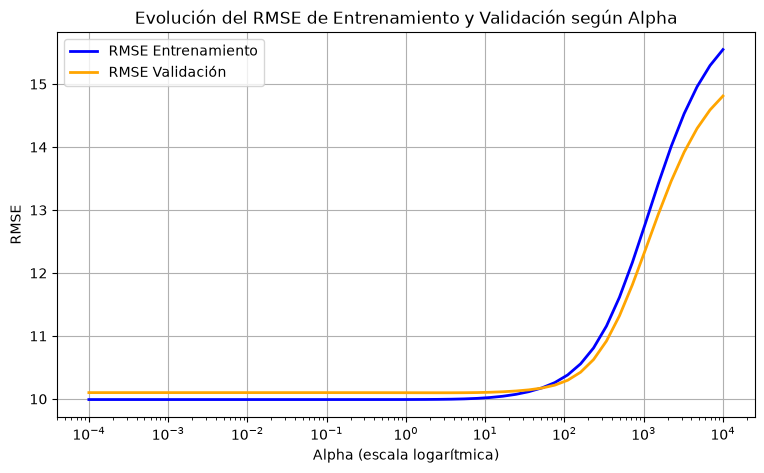

Mejor Alpha seleccionado por validación: 2.5595

RMSE de prueba del modelo final (MyRidge): 11.1975

--- VERIFICACIÓN ESTRICTA CON SKLEARN (ESTANDARIZADO) ---
Coeficientes coinciden: True
Intercepto coincide: True
R2 coincide: True
RMSE coincide: True


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge as SklearnRidge

# 1. Estandarizar las características (ajustar únicamente con el conjunto de entrenamiento)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Escoger alpha por validación (Hold-out / grilla logarítmica)
alphas = np.logspace(-4, 4, 50)
train_rmse_list = []
val_rmse_list = []

# Subdividir el entrenamiento para validación interna
X_sub_train, X_val, y_sub_train, y_val = train_test_split(
    X_train_scaled, y_train, test_size=0.20, random_state=42
)

for a in alphas:
    modelo_temp = MyRidge(alpha=a)
    modelo_temp.fit(X_sub_train, y_sub_train)
    train_rmse_list.append(modelo_temp.rmse(X_sub_train, y_sub_train))
    val_rmse_list.append(modelo_temp.rmse(X_val, y_val))

# Graficar el RMSE de entrenamiento y validación en función de Alpha
plt.figure(figsize=(9, 5))
plt.plot(alphas, train_rmse_list, label="RMSE Entrenamiento", color="blue", linewidth=2)
plt.plot(alphas, val_rmse_list, label="RMSE Validación", color="orange", linewidth=2)
plt.xscale("log")
plt.xlabel("Alpha (escala logarítmica)")
plt.ylabel("RMSE")
plt.title("Evolución del RMSE de Entrenamiento y Validación según Alpha")
plt.legend()
plt.grid(True)
plt.show()

# 3. Seleccionar el mejor alpha
best_alpha = alphas[np.argmin(val_rmse_list)]
print(f"Mejor Alpha seleccionado por validación: {best_alpha:.4f}")

# 4. Entrenar el modelo final con MyRidge usando el mejor alpha
modelo_final = MyRidge(alpha=best_alpha)
modelo_final.fit(X_train_scaled, y_train)

rmse_prueba_final = modelo_final.rmse(X_test_scaled, y_test)
print(f"\nRMSE de prueba del modelo final (MyRidge): {rmse_prueba_final:.4f}")

# 5. Verificación estricta con np.allclose frente a sklearn Ridge
sk_ridge = SklearnRidge(alpha=best_alpha)
sk_ridge.fit(X_train_scaled, y_train)

print("\n--- VERIFICACIÓN ESTRICTA CON SKLEARN (ESTANDARIZADO) ---")
print("Coeficientes coinciden:", np.allclose(modelo_final.coef_, sk_ridge.coef_))
print("Intercepto coincide:", np.allclose(modelo_final.intercept_, sk_ridge.intercept_))
print("R2 coincide:", np.allclose(modelo_final.score(X_test_scaled, y_test), sk_ridge.score(X_test_scaled, y_test)))
print("RMSE coincide:", np.allclose(modelo_final.rmse(X_test_scaled, y_test), np.sqrt(mean_squared_error(y_test, sk_ridge.predict(X_test_scaled)))))

## Punto 4. Ridge vs. Lasso

En este último apartado se comparan los modelos de regularización Ridge (norma $L_2$) y Lasso (norma $L_1$) sobre las características estandarizadas, analizando sus coeficientes, caminos de regularización y la capacidad de selección de variables de Lasso.

Mejor Alpha Ridge: 1.2068
Mejor Alpha Lasso: 0.0029

========== TABLA COMPARATIVA DE COEFICIENTES ==========


,Caracteristica,MyRidge,Ridge_SK,Lasso_SK
0,cement,11.6122,11.8683,12.0433
1,blast_furnace_slag,7.9330,8.1878,8.3600
2,fly_ash,4.9938,5.2192,5.3732
3,water,-3.1708,-2.9996,-2.8864
4,superplasticizer,1.9703,1.9694,1.9633
5,coarse_aggregate,0.8543,1.0274,1.1400
6,fine_aggregate,1.2147,1.4438,1.5960
7,age,6.8433,6.8698,6.8865



Número de coeficientes llevados a cero por Lasso: 0
Lasso no eliminó ninguna característica con este alpha óptimo.


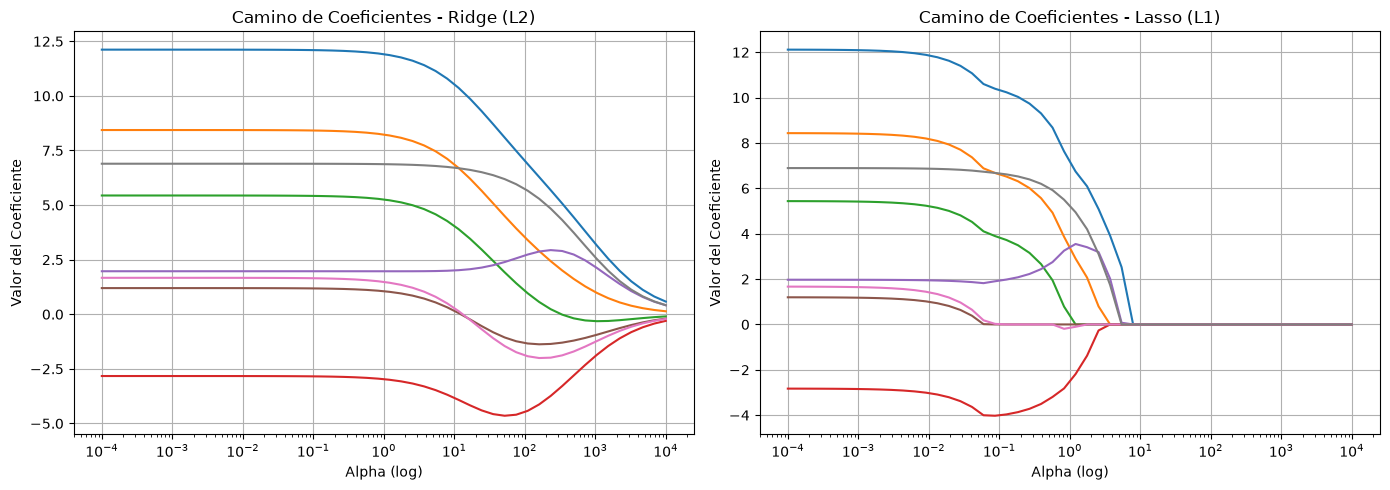

In [11]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV

# 1. Búsqueda de hiperparámetros con GridSearchCV para Ridge y Lasso
ridge_cv = GridSearchCV(SklearnRidge(), {'alpha': alphas}, cv=5, scoring='neg_root_mean_squared_error')
ridge_cv.fit(X_train_scaled, y_train)

lasso_cv = GridSearchCV(Lasso(max_iter=10000), {'alpha': alphas}, cv=5, scoring='neg_root_mean_squared_error')
lasso_cv.fit(X_train_scaled, y_train)

best_ridge_alpha = ridge_cv.best_params_['alpha']
best_lasso_alpha = lasso_cv.best_params_['alpha']

print(f"Mejor Alpha Ridge: {best_ridge_alpha:.4f}")
print(f"Mejor Alpha Lasso: {best_lasso_alpha:.4f}")

# Entrenar modelos finales
ridge_model = SklearnRidge(alpha=best_ridge_alpha).fit(X_train_scaled, y_train)
lasso_model = Lasso(alpha=best_lasso_alpha, max_iter=10000).fit(X_train_scaled, y_train)

# 2. Tabla comparativa de coeficientes lado a lado
columnas_features = df.drop(columns=[objetivo]).columns
df_coefs = pd.DataFrame({
    "Caracteristica": columnas_features,
    "MyRidge": modelo_final.coef_,
    "Ridge_SK": ridge_model.coef_,
    "Lasso_SK": lasso_model.coef_
})

print("\n========== TABLA COMPARATIVA DE COEFICIENTES ==========")
display(df_coefs.round(4))

# 3. Analizar coeficientes llevados a cero en Lasso
coefs_cero = np.sum(lasso_model.coef_ == 0)
features_eliminadas = columnas_features[lasso_model.coef_ == 0]
print(f"\nNúmero de coeficientes llevados a cero por Lasso: {coefs_cero}")
if coefs_cero > 0:
    print(f"Features eliminadas por Lasso: {list(features_eliminadas)}")
else:
    print("Lasso no eliminó ninguna característica con este alpha óptimo.")

# 4. Gráficos de caminos de coeficientes (Coefficient Paths)
ridge_coefs_path = []
lasso_coefs_path = []

for a in alphas:
    r = SklearnRidge(alpha=a).fit(X_train_scaled, y_train)
    l = Lasso(alpha=a, max_iter=10000).fit(X_train_scaled, y_train)
    ridge_coefs_path.append(r.coef_)
    lasso_coefs_path.append(l.coef_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(alphas, ridge_coefs_path)
axes[0].set_xscale("log")
axes[0].set_title("Camino de Coeficientes - Ridge (L2)")
axes[0].set_xlabel("Alpha (log)")
axes[0].set_ylabel("Valor del Coeficiente")
axes[0].grid(True)

axes[1].plot(alphas, lasso_coefs_path)
axes[1].set_xscale("log")
axes[1].set_title("Camino de Coeficientes - Lasso (L1)")
axes[1].set_xlabel("Alpha (log)")
axes[1].set_ylabel("Valor del Coeficiente")
axes[1].grid(True)

plt.tight_layout()
plt.show()